# Reto S13 · «Informe visual para dirección» · equipo «Las Palmeras» (entrega de referencia)

**Pregunta de Marcos (dirección de TurisData):** *¿podemos fiarnos del modelo de cancelaciones, qué lo mueve y cuánto vale?*

**Qué hace este cuaderno:** carga nuestro mejor modelo del curso (la regresión logística: la más simple de las que comparamos y de rendimiento parecido), calcula **sobre el test** la matriz de confusión, la curva ROC, la importancia de variables y el ahorro en euros, y dibuja el panel de una página `informe_visual_panel.png`. Como extras, compara dos umbrales y dos modelos con los costes, mira el rendimiento por canal y por país y fija las versiones.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (segundos). `SEMILLA = 42`; sale siempre el mismo PNG y las mismas cifras. La primera celda descarga los datos.

**Costes (hipótesis anotada, acordada con el docente):** cada cancelación que no detectamos cuesta **50 €** (`COSTE_FN`) y cada falsa alarma **30 €** (`COSTE_FP`).

**Uso de la IA (declarado):** la usamos para (1) entender la importancia por permutación y (2) revisar la redacción de los títulos. Comprobamos que las cifras de los títulos salen de las variables del cuaderno y que todo se calcula con el test. Cambiamos un título de la IA que decía «el depósito evita las cancelaciones»: el gráfico solo muestra lo que pesa en el modelo, no la causa.

## 0. Preparación

In [1]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")

## Parámetros del informe

In [3]:
# >>> EDITA: tus costes y tu umbral (el titular se construye más abajo, con las cifras del test)
CLIENTE = "TurisData Canarias · Dirección de Ingresos"
AUTORES = "Equipo Las Palmeras"
COSTE_FN = 50   # € que perdemos por cada cancelación que el modelo no detecta (hipótesis acordada con el docente)
COSTE_FP = 30   # € que cuesta tratar como "en riesgo" a quien sí viene
UMBRAL = 0.35   # a partir de qué probabilidad avisamos (se justifica con el gráfico de costes de la sección 3)
MODELO = "regresión logística"   # nombre del modelo que aparece en el pie

def euros(x):
    """16590 → '16.590 €' (puntos para los miles, como se escribe en español)."""
    return f"{x:,.0f}".replace(",", ".") + " €"

## 1. Datos y modelo
Nuestro mejor modelo del curso: regresión logística con el preprocesado dentro del `Pipeline` (se ajusta solo con el entrenamiento). Todo lo que sigue se calcula con el **test**, que el modelo no ha visto.

In [4]:
reservas = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
reservas["mes_llegada"] = reservas["fecha_llegada"].dt.month
X = reservas.drop(columns=["id_reserva", "fecha_reserva", "fecha_llegada", "cancelada"])
y = reservas["cancelada"]
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)

categoricas = X.select_dtypes("object").columns.tolist()
numericas = [c for c in X.columns if c not in categoricas]
prep = ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
modelo = Pipeline([("prep", prep), ("m", LogisticRegression(max_iter=2000))]).fit(X_ent, y_ent)   # >>> EDITA
prob = modelo.predict_proba(X_test)[:, 1]
print("AUC en prueba:", round(roc_auc_score(y_test, prob), 3), "· reservas de prueba:", len(y_test))

AUC en prueba: 0.744 · reservas de prueba: 1500


## 2. Cálculos que alimentan el panel

In [5]:
pred = (prob >= UMBRAL).astype(int)
cm = confusion_matrix(y_test, pred, normalize="true")
fpr, tpr, _ = roc_curve(y_test, prob)
auc = roc_auc_score(y_test, prob)
res = permutation_importance(modelo, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEMILLA)
importancias = pd.Series(res.importances_mean, index=X_test.columns).sort_values(ascending=False)

fn = int(((pred == 0) & (y_test == 1)).sum())
fp = int(((pred == 1) & (y_test == 0)).sum())
coste_con_modelo = COSTE_FN * fn + COSTE_FP * fp
coste_sin_modelo = COSTE_FN * int((y_test == 1).sum())   # sin modelo: no detectamos ninguna cancelación
ahorro = coste_sin_modelo - coste_con_modelo
print(f"Coste sin modelo: {euros(coste_sin_modelo)} · con modelo: {euros(coste_con_modelo)} · ahorro: {euros(ahorro)} (en {len(y_test)} reservas de prueba)")

# «Falsas alarmas» puede querer decir dos cosas distintas; elige la que cuentas y di cuál es:
tp = int(((pred == 1) & (y_test == 1)).sum())
print(f"De los avisos, {fp / (fp + tp):.0%} eran falsas alarmas (de cada 10 avisos, {10 * fp / (fp + tp):.0f}).")
print(f"De las reservas que NO cancelan, avisamos por error al {fp / int((y_test == 0).sum()):.0%} (es el dato del gráfico de la matriz).")

Coste sin modelo: 34.400 € · con modelo: 17.810 € · ahorro: 16.590 € (en 1500 reservas de prueba)
De los avisos, 41% eran falsas alarmas (de cada 10 avisos, 4).
De las reservas que NO cancelan, avisamos por error al 49% (es el dato del gráfico de la matriz).


## 3. ¿Por qué ese umbral? Dos umbrales y dos modelos, con los costes
El umbral no es 0,5 por defecto: lo decide el coste de equivocarse en cada sentido.

In [6]:
# Extra · ¿por qué 0,35? Dos umbrales y dos modelos comparados con los costes (todo sobre el test)
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier

def coste_total(y_real, p, umbral):
    pr = (p >= umbral).astype(int)
    fn_ = int(((pr == 0) & (y_real == 1)).sum()); fp_ = int(((pr == 1) & (y_real == 0)).sum())
    return COSTE_FN * fn_ + COSTE_FP * fp_, fn_, fp_

boost = Pipeline([("prep", clone(prep)), ("m", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, random_state=SEMILLA))]).fit(X_ent, y_ent)
prob_boost = boost.predict_proba(X_test)[:, 1]

filas = []
for nombre, p in [("Regresión logística", prob), ("Boosting de árboles", prob_boost)]:
    for u in (0.35, 0.5):
        c, fn_, fp_ = coste_total(y_test.to_numpy(), p, u)
        filas.append({"modelo": nombre, "umbral": u, "AUC": round(roc_auc_score(y_test, p), 3),
                      "detecta": round(1 - fn_ / int((y_test == 1).sum()), 3), "coste": c, "ahorro": coste_sin_modelo - c})
comparacion = pd.DataFrame(filas)
print(comparacion.to_string(index=False))

umbrales = np.round(np.arange(0.10, 0.71, 0.05), 2)
costes_umbral = {float(u): coste_total(y_test.to_numpy(), prob, u)[0] for u in umbrales}
umbral_optimo = min(costes_umbral, key=costes_umbral.get)
print("Coste por umbral (logística):", {u: euros(c) for u, c in costes_umbral.items()})
print(f"Umbral con menos coste: {umbral_optimo:.2f} · el elegido ({UMBRAL:.2f}) cuesta {euros(costes_umbral[UMBRAL])}")
assert abs(umbral_optimo - UMBRAL) <= 0.05, "El umbral elegido debe estar cerca del que minimiza el coste."
print("✔ El umbral elegido está justificado por los costes")

             modelo  umbral   AUC  detecta  coste  ahorro
Regresión logística    0.35 0.744    0.828  17810   16590
Regresión logística    0.50 0.744    0.616  19710   14690
Boosting de árboles    0.35 0.734    0.811  19190   15210
Boosting de árboles    0.50 0.734    0.619  20420   13980
Coste por umbral (logística): {0.1: '22.740 €', 0.15: '21.550 €', 0.2: '20.280 €', 0.25: '19.440 €', 0.3: '18.540 €', 0.35: '17.810 €', 0.4: '18.660 €', 0.45: '19.360 €', 0.5: '19.710 €', 0.55: '21.800 €', 0.6: '22.830 €', 0.65: '23.840 €', 0.7: '25.230 €'}
Umbral con menos coste: 0.35 · el elegido (0.35) cuesta 17.810 €
✔ El umbral elegido está justificado por los costes


## 4. Rendimiento por canal y por país
Una medida para la nota de IA responsable: ¿detecta igual en todos los grupos?

In [7]:
# Extra · ¿el modelo funciona igual en todos los canales y países? (con el umbral elegido, sobre el test)
sub = X_test.copy()
sub["real"] = y_test.to_numpy(); sub["aviso"] = pred

def por_grupo(columna):
    g = sub.groupby(columna).apply(lambda d: pd.Series({
        "reservas": len(d), "cancelan": d["real"].mean(),
        "detecta": ((d["aviso"] == 1) & (d["real"] == 1)).sum() / max((d["real"] == 1).sum(), 1),
        "falsas_alarmas": ((d["aviso"] == 1) & (d["real"] == 0)).sum() / max((d["real"] == 0).sum(), 1)}), include_groups=False)
    return g.round(2).sort_values("detecta", ascending=False)

por_canal = por_grupo("canal")
por_pais = por_grupo("pais_origen")
print("Por canal:"); print(por_canal.to_string())
print("\nPor país:"); print(por_pais.to_string())
dif_canal = round(float(por_canal["detecta"].max() - por_canal["detecta"].min()), 2)
dif_pais = round(float(por_pais["detecta"].max() - por_pais["detecta"].min()), 2)
print(f"\nDiferencia máxima de detección: {dif_canal:.2f} entre canales y {dif_pais:.2f} entre países")

Por canal:
                   reservas  cancelan  detecta  falsas_alarmas
canal                                                         
web_intermediaria     738.0      0.54     0.91            0.65
agencia               295.0      0.43     0.81            0.47
empresa                79.0      0.48     0.74            0.51
directo               388.0      0.32     0.62            0.29

Por país:
             reservas  cancelan  detecta  falsas_alarmas
pais_origen                                             
IT               76.0      0.42     0.94            0.45
FR               71.0      0.44     0.90            0.50
Nordicos        110.0      0.48     0.89            0.46
DE              207.0      0.50     0.84            0.45
UK              369.0      0.47     0.83            0.53
ES              383.0      0.46     0.81            0.48
NL               84.0      0.49     0.80            0.51
otros           161.0      0.40     0.80            0.51

Diferencia máxima de detecció

## 5. El panel de una página
Título del panel = decisión; título de cada gráfico = conclusión; ejes con nombre; barras desde 0; pocos colores.

In [8]:
# Títulos-conclusión: salen de las variables, así nunca se desalinean con el gráfico
NOMBRES = {"antelacion_dias": "la antelación de la reserva", "deposito": "el depósito", "canal": "el canal de venta", "tarifa": "la tarifa",
           "pais_origen": "el país de origen", "precio_noche": "el precio por noche", "noches": "las noches"}
lider = importancias.index[0]
TITULAR = f"Pedir depósito y avisar a las reservas de riesgo alto ahorra unos {euros(ahorro)} por cada {len(y_test):,}".replace(",", ".") + " reservas"
titulos = [
    f"Detectamos el {cm[1, 1]:.0%} de las cancelaciones;\navisamos por error al {cm[0, 1]:.0%} de quien no cancela",
    "Acierta bastante mejor que el azar, pero no es perfecto",
    f"Lo que más pesa en una cancelación: {NOMBRES.get(lider, lider)}",
    f"Con el modelo perdemos {euros(ahorro)} menos en {len(y_test):,}".replace(",", ".") + " reservas",
]
print(TITULAR)

Pedir depósito y avisar a las reservas de riesgo alto ahorra unos 16.590 € por cada 1.500 reservas


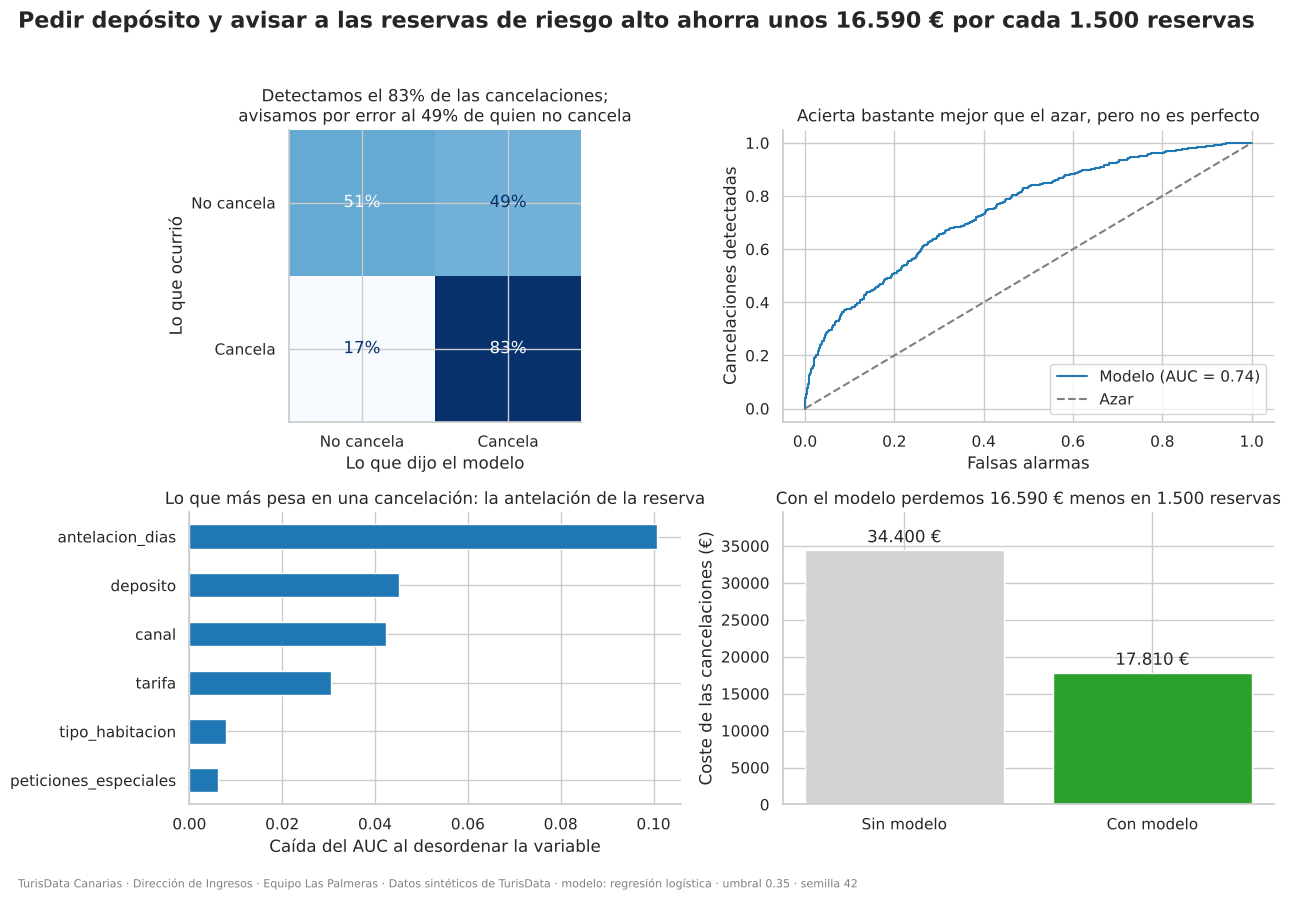

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle(TITULAR, fontsize=16, fontweight="bold", x=0.02, ha="left")

# (1) Fiabilidad: matriz de confusión
ConfusionMatrixDisplay(cm, display_labels=["No cancela", "Cancela"]).plot(ax=ax[0, 0], cmap="Blues", values_format=".0%", colorbar=False)
ax[0, 0].set_title(titulos[0])
ax[0, 0].set_xlabel("Lo que dijo el modelo"); ax[0, 0].set_ylabel("Lo que ocurrió")

# (2) Fiabilidad: curva ROC
ax[0, 1].plot(fpr, tpr, color="tab:blue", label=f"Modelo (AUC = {auc:.2f})")
ax[0, 1].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ax[0, 1].set_title(titulos[1])
ax[0, 1].set_xlabel("Falsas alarmas"); ax[0, 1].set_ylabel("Cancelaciones detectadas"); ax[0, 1].legend(loc="lower right")

# (3) Qué mueve el resultado
importancias.head(6)[::-1].plot.barh(ax=ax[1, 0], color="tab:blue")
ax[1, 0].set_title(titulos[2])
ax[1, 0].set_xlabel("Caída del AUC al desordenar la variable")

# (4) Valor para el negocio
valores = [coste_sin_modelo, coste_con_modelo]
barras = ax[1, 1].bar(["Sin modelo", "Con modelo"], valores, color=["lightgray", "tab:green"])
ax[1, 1].bar_label(barras, labels=[euros(v) for v in valores], padding=3)
ax[1, 1].set_title(titulos[3])
ax[1, 1].set_ylabel("Coste de las cancelaciones (€)"); ax[1, 1].set_ylim(0, max(valores) * 1.15)

fig.text(0.02, 0.005, f"{CLIENTE} · {AUTORES} · Datos sintéticos de TurisData · modelo: {MODELO} · umbral {UMBRAL:.2f} · semilla {SEMILLA}",
         fontsize=8, color="gray")
sns.despine()
plt.tight_layout(rect=(0, 0.02, 1, 0.96))
plt.savefig("informe_visual_panel.png", dpi=150)
plt.show()

## 6. Cifras para el informe y versiones

In [10]:
import json, sys, sklearn, matplotlib, seaborn
cifras = {
    "n_total": int(len(reservas)), "n_test": int(len(y_test)), "periodo": [str(reservas["fecha_llegada"].min().date()), str(reservas["fecha_llegada"].max().date())],
    "auc": round(float(auc), 3), "detecta": round(float(cm[1, 1]), 3), "falsas": round(float(cm[0, 1]), 3),
    "fn": fn, "fp": fp, "tp": tp, "n_cancelan_test": int((y_test == 1).sum()),
    "falsas_de_avisos": round(fp / (fp + tp), 3), "avisos": fp + tp,
    "coste_sin": int(coste_sin_modelo), "coste_con": int(coste_con_modelo), "ahorro": int(ahorro),
    "importancias": {k: round(float(v), 3) for k, v in importancias.head(4).items()}, "lider": lider,
    "titulos": titulos, "titular": TITULAR, "umbral": UMBRAL, "coste_fn": COSTE_FN, "coste_fp": COSTE_FP,
    "comparacion": comparacion.to_dict(orient="records"), "umbral_optimo": umbral_optimo,
    "coste_umbral": {str(k): int(v) for k, v in costes_umbral.items()},
    "por_canal": por_canal.to_dict(orient="index"), "por_pais": por_pais.to_dict(orient="index"),
    "dif_canal": dif_canal, "dif_pais": dif_pais,
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, matplotlib {matplotlib.__version__}, seaborn {seaborn.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"n_total": 6000, "n_test": 1500, "periodo": ["2024-01-13", "2026-12-04"], "auc": 0.744, "detecta": 0.828, "falsas": 0.489, "fn": 118, "fp": 397, "tp": 570, "n_cancelan_test": 688, "falsas_de_avisos": 0.411, "avisos": 967, "coste_sin": 34400, "coste_con": 17810, "ahorro": 16590, "importancias": {"antelacion_dias": 0.101, "deposito": 0.045, "canal": 0.042, "tarifa": 0.031}, "lider": "antelacion_dias", "titulos": ["Detectamos el 83% de las cancelaciones;\navisamos por error al 49% de quien no cancela", "Acierta bastante mejor que el azar, pero no es perfecto", "Lo que más pesa en una cancelación: la antelación de la reserva", "Con el modelo perdemos 16.590 € menos en 1.500 reservas"], "titular": "Pedir depósito y avisar a las reservas de riesgo alto ahorra unos 16.590 € por cada 1.500 reservas", "umbral": 0.35, "coste_fn": 50, "coste_fp": 30, "comparacion": [{"modelo": "Regresión logística", "umbral": 0.35, "AUC": 0.744, "detecta": 0.828, "coste": 17810, "ahorro": 16590}, {"modelo": "Reg